# 🧠 MVP-4 — Imagination / Dyna Planning (Mental Time Travel)
## 🎯 What Changes at MVP-4

Now the agent will:
1. Pause
2. Imagine multiple future trajectories
3. Evaluate them
4. Choose the best action
5. Then move

**This is explicit hippocampal planning.**

In [47]:
import numpy as np
import matplotlib.pyplot as plt

In [48]:
class MazeEnv:
    def __init__(self, maze):
        self.maze = maze
        self.height, self.width = maze.shape
        self.start_pos = tuple(np.argwhere(maze == 2)[0])
        self.goal_pos = tuple(np.argwhere(maze == 3)[0])
        self.reset()

    def reset(self):
        self.agent_pos = self.start_pos
        return self.agent_pos

    def step(self, action):
        moves = {
            0: (-1, 0),  # up
            1: (1, 0),   # down
            2: (0, -1),  # left
            3: (0, 1)    # right
        }

        dx, dy = moves[action]
        x, y = self.agent_pos
        nx, ny = x + dx, y + dy

        # Check boundaries and walls
        if 0 <= nx < self.height and 0 <= ny < self.width:
            if self.maze[nx, ny] != 1:
                self.agent_pos = (nx, ny)

        reward = 1 if self.agent_pos == self.goal_pos else 0
        done = self.agent_pos == self.goal_pos

        return self.agent_pos, reward, done


In [49]:
def render(
    env,
    imagined_paths=None,
    chosen_path=None,
    title="Maze Environment"
):
    """
    imagined_paths: list of lists of (x, y) tuples
    chosen_path: list of (x, y) tuples
    """

    fig, ax = plt.subplots(figsize=(5, 5))

    # --- Draw maze background ---
    for x in range(env.height):
        for y in range(env.width):
            if env.maze[x, y] == 1:      # wall
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="black"))
            else:                        # free space
                ax.add_patch(plt.Rectangle((y, x), 1, 1, color="white"))

    # --- Draw start & goal ---
    sx, sy = env.start_pos
    gx, gy = env.goal_pos

    ax.text(sy + 0.5, sx + 0.5, "S", ha="center", va="center", fontsize=12)
    ax.text(gy + 0.5, gx + 0.5, "G", ha="center", va="center", fontsize=12)

    # --- Draw imagined trajectories (future use) ---
    if imagined_paths is not None:
        for path in imagined_paths:
            xs = [y + 0.5 for x, y in path]
            ys = [x + 0.5 for x, y in path]
            ax.plot(xs, ys, linestyle="dotted", alpha=0.4, color="blue")

    # --- Draw chosen path (future use) ---
    if chosen_path is not None:
        xs = [y + 0.5 for x, y in chosen_path]
        ys = [x + 0.5 for x, y in chosen_path]
        ax.plot(xs, ys, linewidth=2.5, color="red")

    # --- Draw agent ---
    ax.scatter(
        env.agent_pos[1] + 0.5,
        env.agent_pos[0] + 0.5,
        s=200,
        color="orange",
        zorder=5
    )

    # --- Formatting ---
    ax.set_xlim(0, env.width)
    ax.set_ylim(env.height, 0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_aspect("equal")

    plt.show()


In [50]:
import numpy as np
maze = np.array([
    [2, 0, 0, 1, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 1, 0],
    [0, 1, 1, 1, 0, 1, 0],
    [0, 0, 0, 0, 0, 0, 3]
])
HEIGHT, WIDTH = maze.shape

env = MazeEnv(maze)

In [51]:
class WorldModel:
    def __init__(self):
        # (state, action) -> next_state
        self.transitions = {}

        # (state, action) -> reward
        self.rewards = {}

    def update(self, state, action, next_state, reward):
        self.transitions[(state, action)] = next_state
        self.rewards[(state, action)] = reward

    def predict_next_state(self, state, action):
        return self.transitions.get((state, action), None)

    def predict_reward(self, state, action):
        return self.rewards.get((state, action), 0)


## Imagine Rollout Function

In [63]:
def imagine_rollout(world_model, start_state, first_action, horizon):
    """
    Roll out a single imagined trajectory starting with first_action.
    Returns: path (list of states), cumulative reward
    """
    state = start_state
    path = [state]
    total_reward = 0
    action = first_action

    for _ in range(horizon):
        next_state = world_model.predict_next_state(state, action)
        reward = world_model.predict_reward(state, action)

        if next_state is None:
            break  # unknown transition

        total_reward += reward
        path.append(next_state)

        # after first step, choose random imagined actions
        state = next_state
        action = random.randint(0, 3)

    return path, total_reward


In [64]:
import random

class Agent:
    def __init__(
        self,
        action_space=4,
        epsilon=0.1,
        imagination_horizon=6,
        imagination_rollouts=10
    ):
        self.action_space = action_space
        self.epsilon = epsilon

        self.imagination_horizon = imagination_horizon
        self.imagination_rollouts = imagination_rollouts

        self.world_model = WorldModel()

    def learn_model(self, state, action, next_state, reward):
        self.world_model.update(state, action, next_state, reward)

    def plan_and_act(self, state):
        """
        Perform imagination-based planning before acting.
        """
        # exploration fallback
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1), None, None

        imagined_paths = []
        action_scores = {}

        for action in range(self.action_space):
            scores = []
            paths = []

            for _ in range(self.imagination_rollouts):
                path, reward = imagine_rollout(
                    self.world_model,
                    state,
                    action,
                    self.imagination_horizon
                )
                scores.append(reward)
                paths.append(path)

            action_scores[action] = sum(scores) / len(scores)
            imagined_paths.extend(paths)

        # choose best action
        best_action = max(action_scores, key=action_scores.get)

        # choose one representative best path
        best_path, _ = imagine_rollout(
            self.world_model,
            state,
            best_action,
            self.imagination_horizon,
        )

        return best_action, imagined_paths, best_path


In [65]:
def run_agent_episode(env, agent, max_steps=50, delay=0.4):
    state = env.reset()
    render(env, title="Agent Starting")

    for step in range(max_steps):

        action, imagined_paths, chosen_path = agent.plan_and_act(state)

        # 🧠 visualize imagination BEFORE acting
        if imagined_paths is not None:
            render(
                env,
                imagined_paths=imagined_paths,
                chosen_path=chosen_path,
                title=f"Thinking (Step {step+1})"
            )

        next_state, reward, done = env.step(action)

        # 🧠 learn from real experience
        agent.learn_model(state, action, next_state, reward)

        state = next_state

        render(env, title=f"Acting (Step {step+1})")

        if done:
            print(f"🎯 Reached goal in {step+1} steps")
            return

    print("❌ Episode ended without reaching goal")


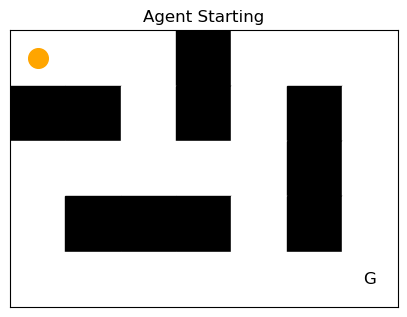

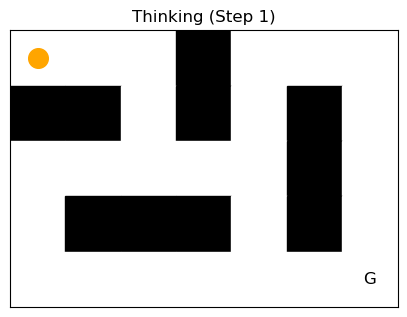

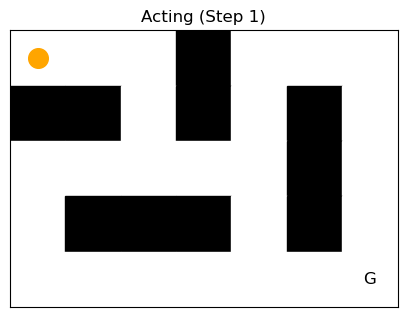

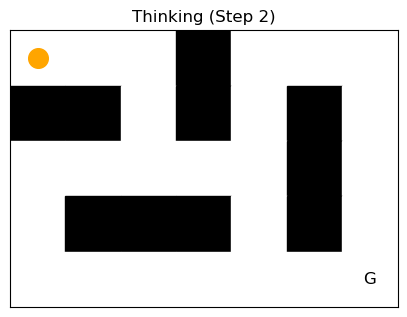

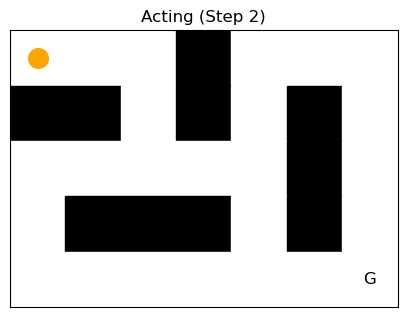

...

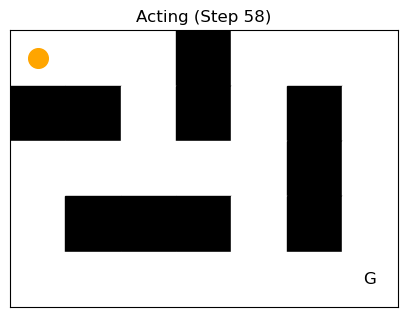

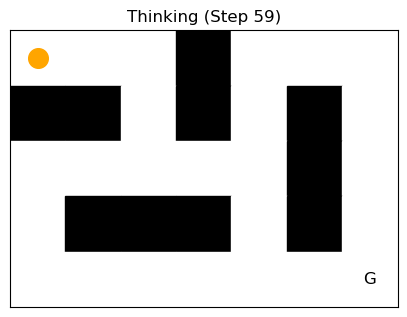

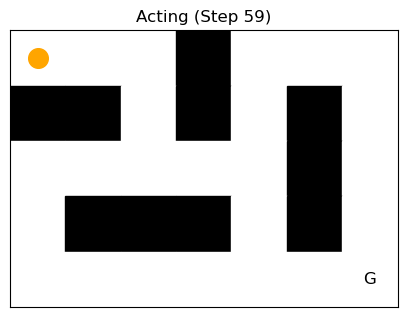

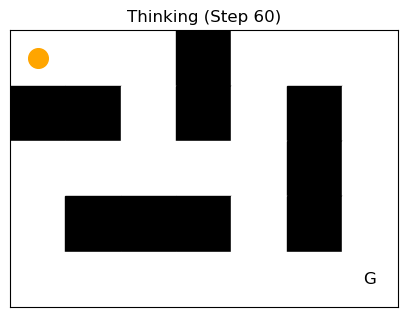

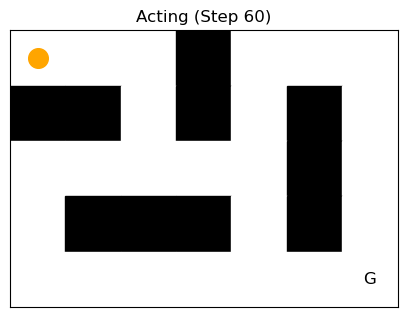

❌ Episode ended without reaching goal


In [66]:
agent = Agent(
    epsilon=0.05,
    imagination_horizon=6,
    imagination_rollouts=12
)

run_agent_episode(env, agent, max_steps=60, delay=0.3)


### The Ball didn't move at all

We’ve just discovered:

`Imagination without sufficient experience can paralyze behavior`

That’s a real phenomenon in:

- hippocampal planning
- model-based RL
- cognitive control

But we still need the agent to recover and explore.

In [67]:
import random

class Agent:
    def __init__(
        self,
        action_space=4,
        epsilon=0.1,
        imagination_horizon=6,
        imagination_rollouts=10
    ):
        self.action_space = action_space
        self.epsilon = epsilon

        self.imagination_horizon = imagination_horizon
        self.imagination_rollouts = imagination_rollouts

        self.world_model = WorldModel()

    def learn_model(self, state, action, next_state, reward):
        self.world_model.update(state, action, next_state, reward)

    def plan_and_act(self, state):
        # --- exploration fallback ---
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1), None, None
    
        imagined_paths = []
        action_scores = {}
    
        for action in range(self.action_space):
            scores = []
            paths = []
    
            for _ in range(self.imagination_rollouts):
                path, reward = imagine_rollout(
                    self.world_model,
                    state,
                    action,
                    self.imagination_horizon
                )
    
                # ignore rollouts with no model knowledge
                if len(path) <= 1:
                    continue
    
                scores.append(reward)
                paths.append(path)
    
            # ✅ only score action if we have valid rollouts
            if len(scores) > 0:
                action_scores[action] = sum(scores) / len(scores)
                imagined_paths.extend(paths)
    
        # 🚑 if nothing is known yet → explore
        if len(action_scores) == 0:
            return random.randint(0, self.action_space - 1), None, None
    
        best_action = max(action_scores, key=action_scores.get)
    
        best_path, _ = imagine_rollout(
            self.world_model,
            state,
            best_action,
            self.imagination_horizon,
            
        )
    
        return best_action, imagined_paths, best_path



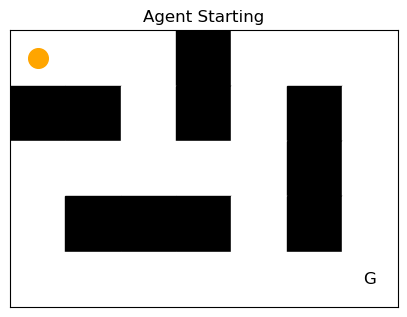

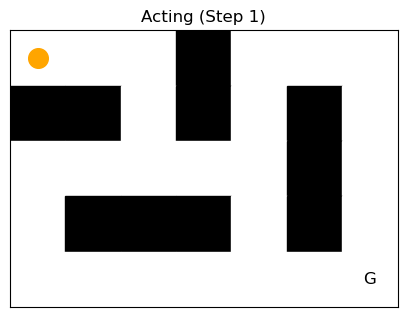

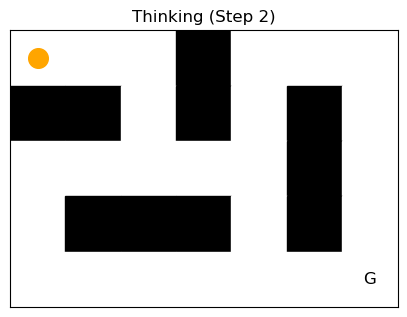

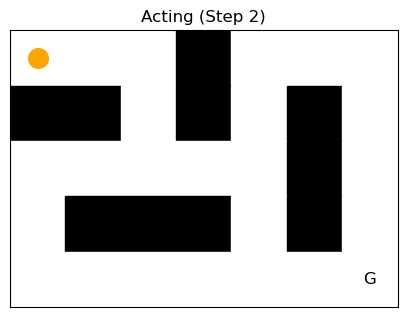

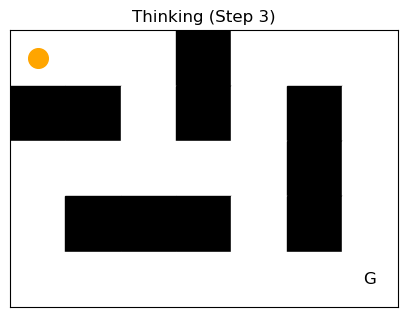

...

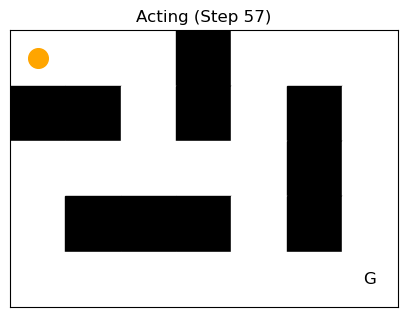

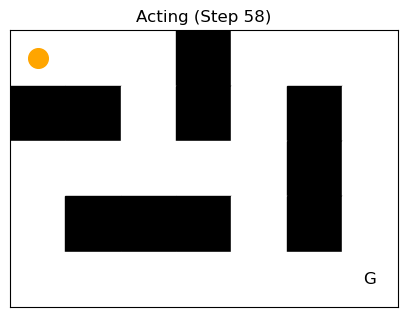

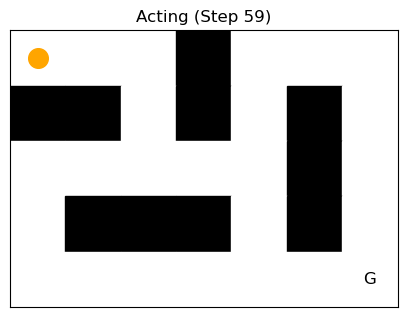

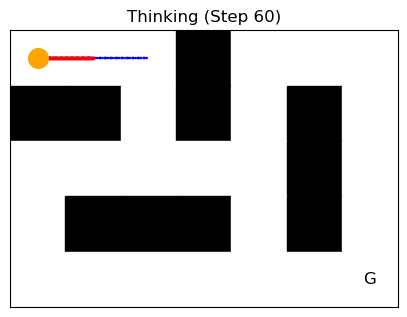

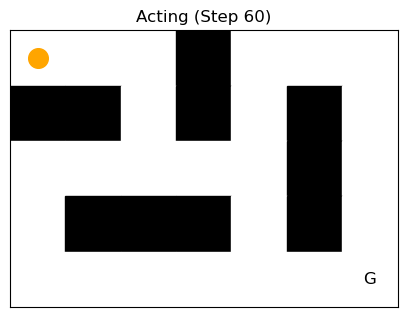

❌ Episode ended without reaching goal


In [68]:
agent = Agent(
    epsilon=0.7,                 # 🔼 more exploration early
    imagination_horizon=6,
    imagination_rollouts=12
)
run_agent_episode(env, agent, max_steps=60, delay=0.3)

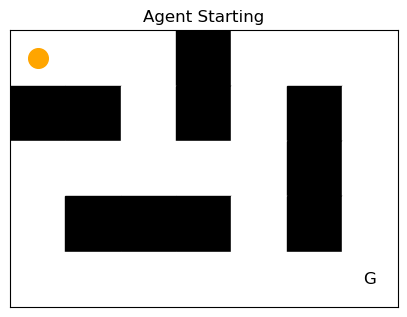

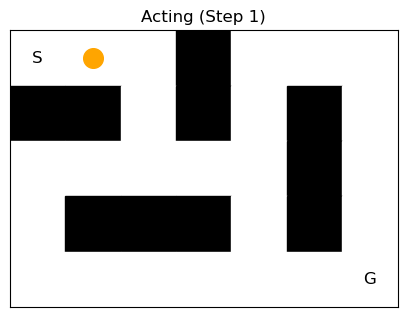

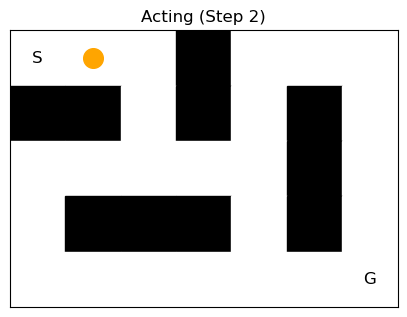

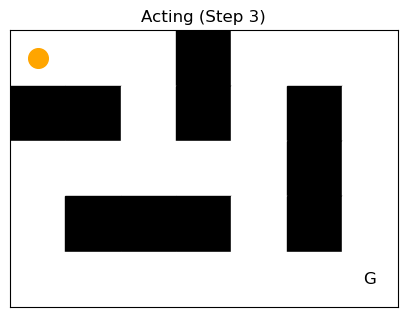

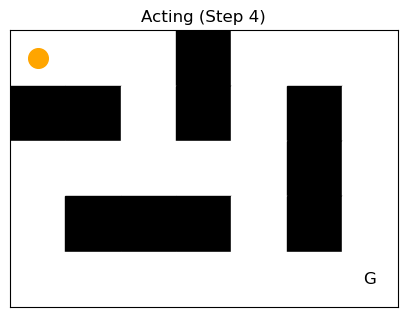

...

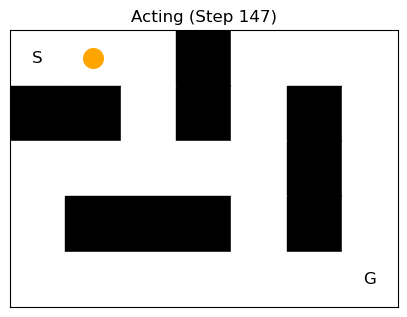

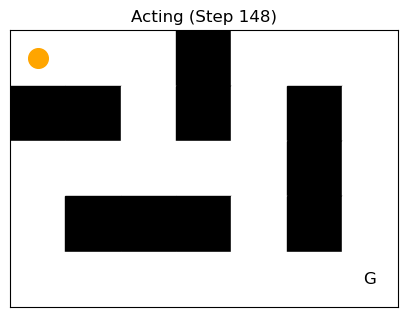

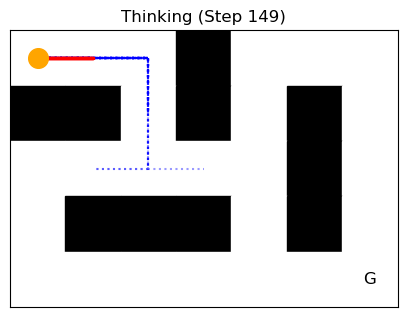

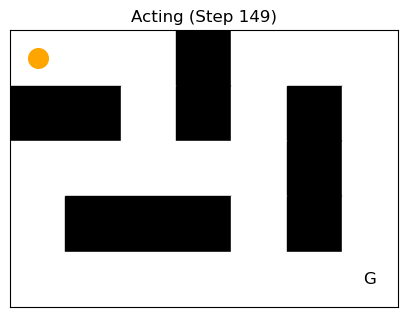

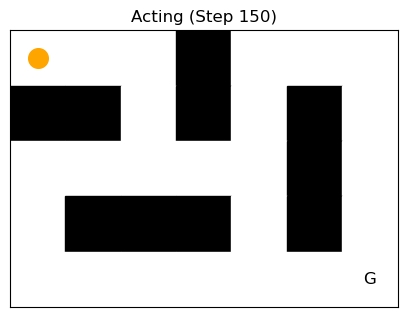

❌ Episode ended without reaching goal


In [69]:
agent = Agent(
    epsilon=0.7,                 # 🔼 more exploration early
    imagination_horizon=8,
    imagination_rollouts=16
)
run_agent_episode(env, agent, max_steps=150, delay=0.3)

In [70]:
print("World model size:", len(agent.world_model.transitions))

World model size: 21


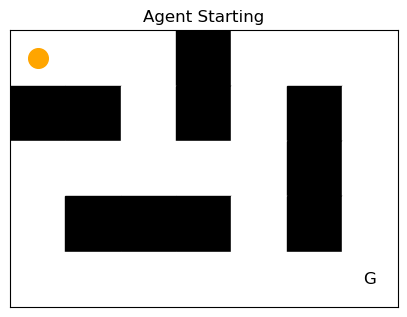

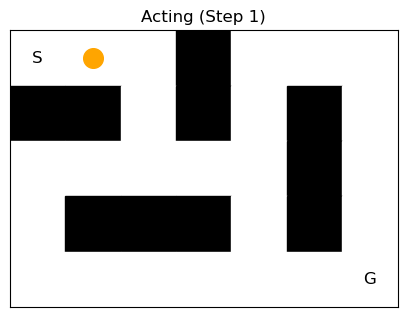

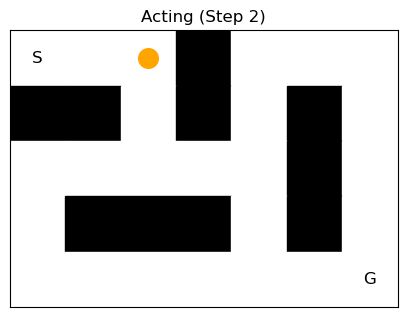

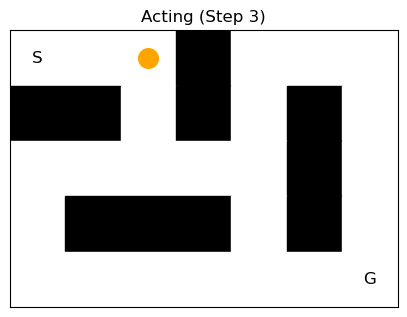

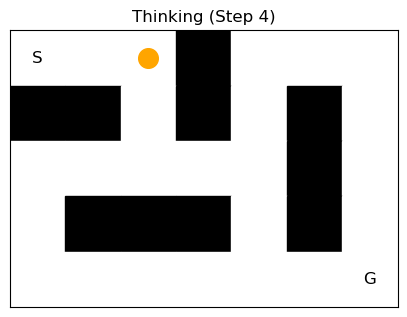

...

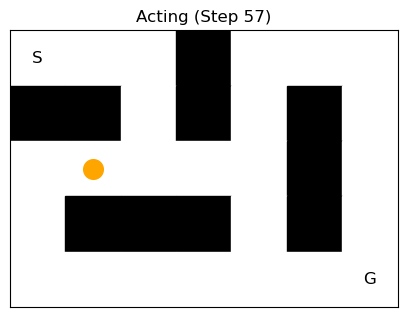

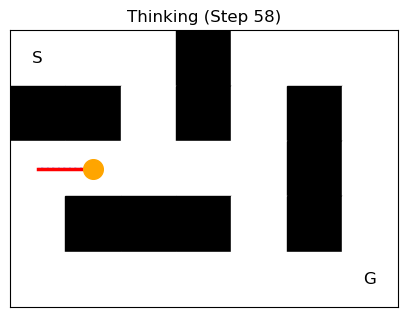

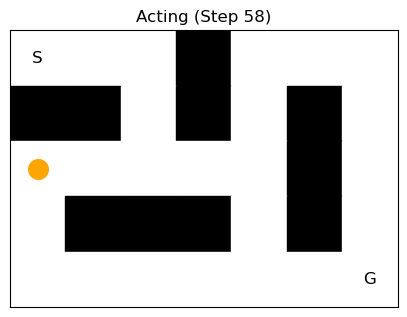

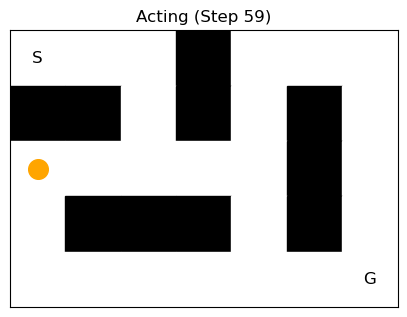

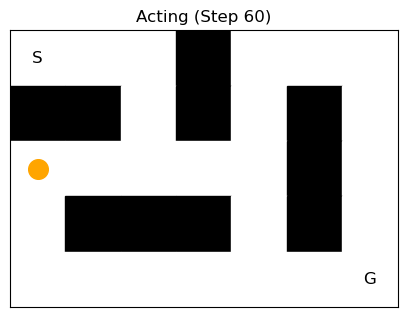

❌ Episode ended without reaching goal


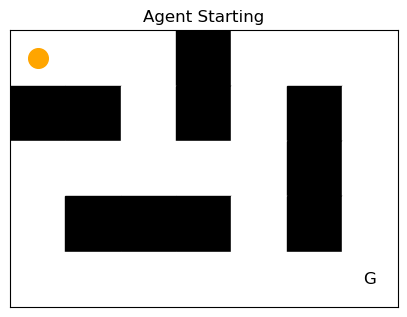

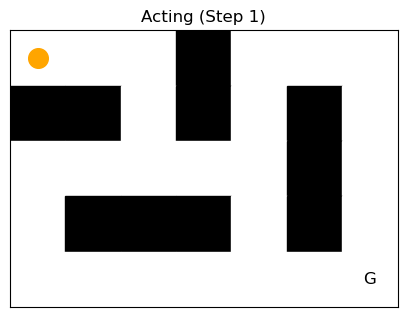

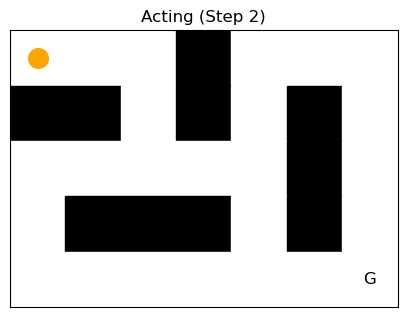

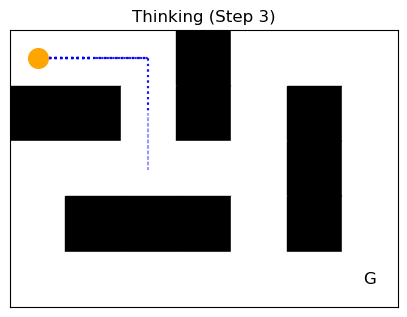

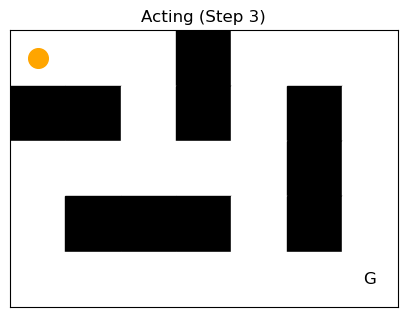

...

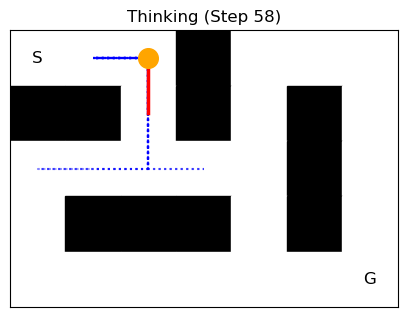

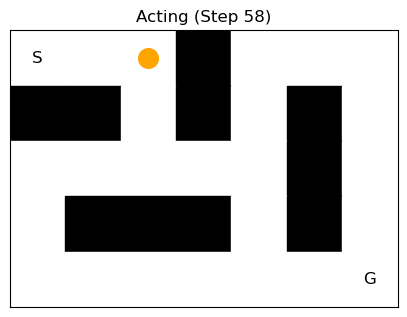

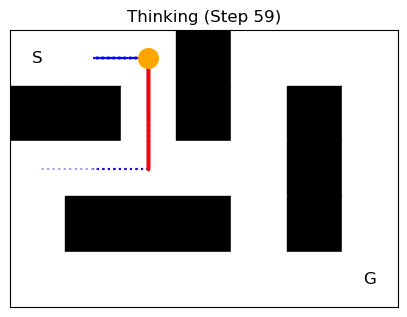

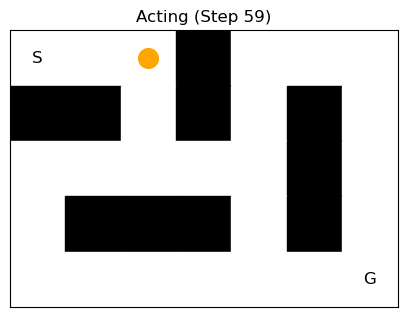

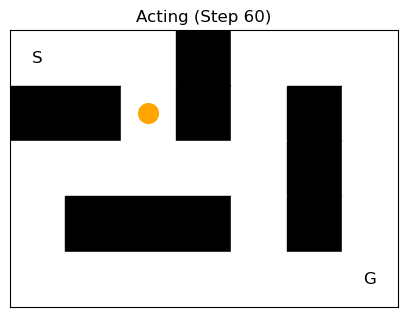

❌ Episode ended without reaching goal


In [71]:
agent = Agent(
    epsilon=0.5,               
    imagination_horizon=6,
    imagination_rollouts=12
)
run_agent_episode(env, agent, max_steps=60, delay=0.3)
run_agent_episode(env, agent, max_steps=60, delay=0.3)

## Next Goal : No-Imagination Ablation

### 🎯 Goal
#### Show that removing imagination collapses behavior, even though:

- the environment is the same

- the world model still exists

- the agent body is unchanged

`Only planning is removed.`

If both behave the same → project fails \
If planner clearly outperforms → project wins

In [72]:
import random

class Agent:
    def __init__(
        self,
        action_space=4,
        epsilon=0.1,
        imagination_horizon=6,
        imagination_rollouts=10
    ):
        self.action_space = action_space
        self.epsilon = epsilon

        self.imagination_horizon = imagination_horizon
        self.imagination_rollouts = imagination_rollouts

        self.world_model = WorldModel()

    def learn_model(self, state, action, next_state, reward):
        self.world_model.update(state, action, next_state, reward)
        
    def act_without_imagination(self, state):
        """
        Baseline: ignore world model and imagination.
        """
        return random.randint(0, self.action_space - 1)

    

    def plan_and_act(self, state):
        """
        Perform imagination-based planning before acting.
        """
        # exploration fallback
        if random.random() < self.epsilon:
            return random.randint(0, self.action_space - 1), None, None

        imagined_paths = []
        action_scores = {}

        for action in range(self.action_space):
            scores = []
            paths = []

            for _ in range(self.imagination_rollouts):
                path, reward = imagine_rollout(
                    self.world_model,
                    state,
                    action,
                    self.imagination_horizon
                )
                scores.append(reward)
                paths.append(path)

            action_scores[action] = sum(scores) / len(scores)
            imagined_paths.extend(paths)

        # choose best action
        best_action = max(action_scores, key=action_scores.get)

        # choose one representative best path
        best_path, _ = imagine_rollout(
            self.world_model,
            state,
            best_action,
            self.imagination_horizon
        )

        return best_action, imagined_paths, best_path



In [73]:
def run_agent_episode_no_imagination(env, agent, max_steps=50, delay=0.3):
    state = env.reset()
    render(env, title="No-Imagination Agent Starting")

    for step in range(max_steps):
        action = agent.act_without_imagination(state)

        next_state, reward, done = env.step(action)

        # still learns the world model (important!)
        agent.learn_model(state, action, next_state, reward)

        state = next_state
        render(env, title=f"No-Imagination Step {step+1}")

        if done:
            print(f"🎯 (No Imagination) Reached goal in {step+1} steps")
            return

    print("❌ (No Imagination) Episode ended without reaching goal")


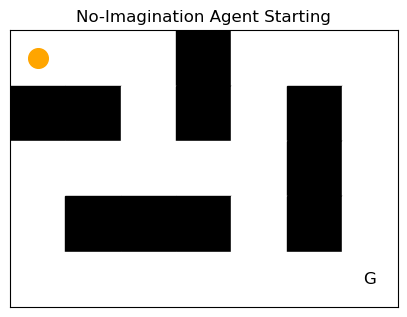

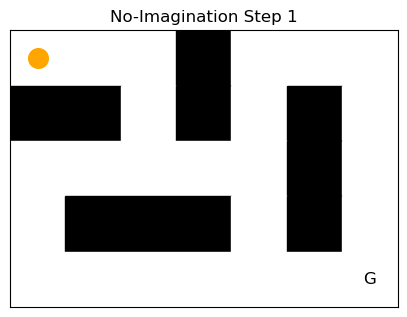

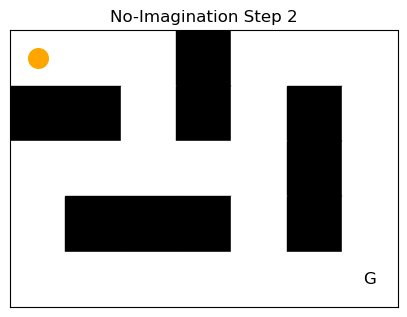

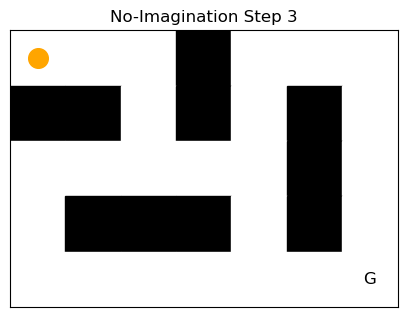

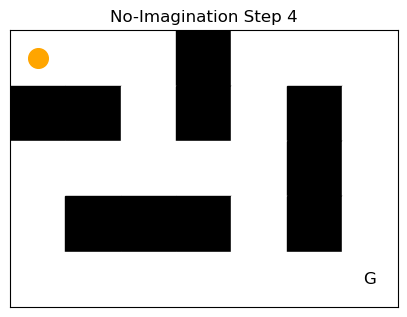

...

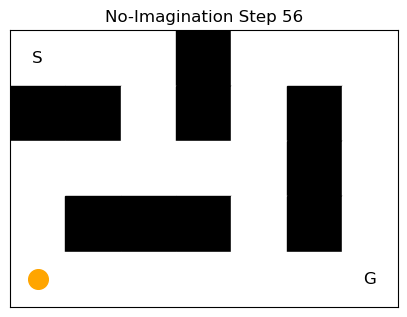

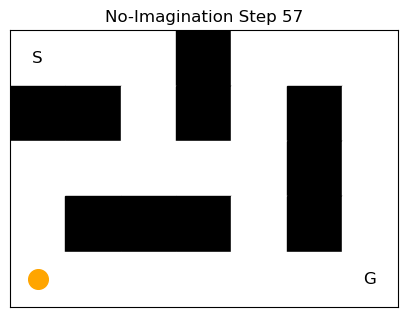

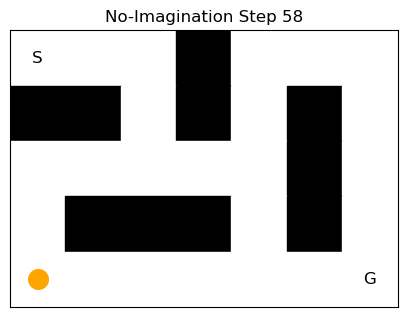

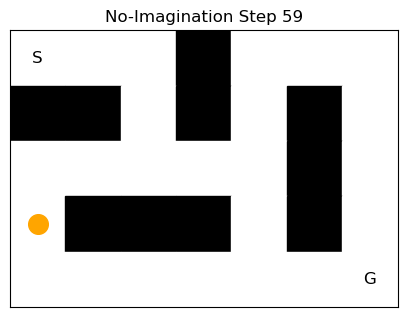

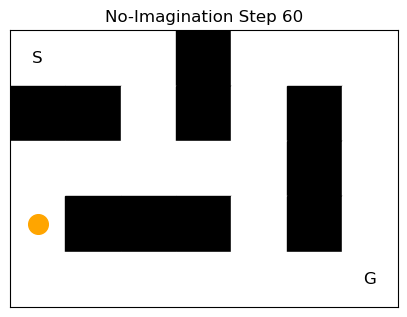

❌ (No Imagination) Episode ended without reaching goal


In [74]:
agent_no_plan = Agent(
    epsilon=0.5,
    imagination_horizon=6,
    imagination_rollouts=12
)

run_agent_episode_no_imagination(env, agent_no_plan, max_steps=60, delay=0.3)


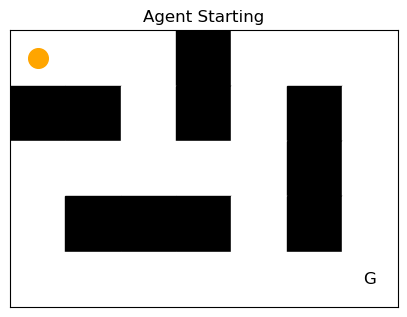

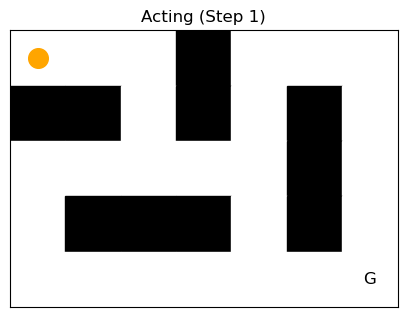

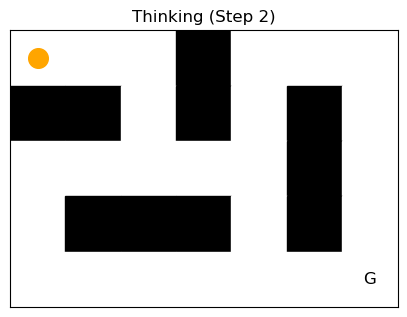

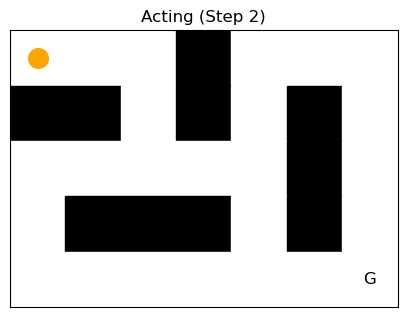

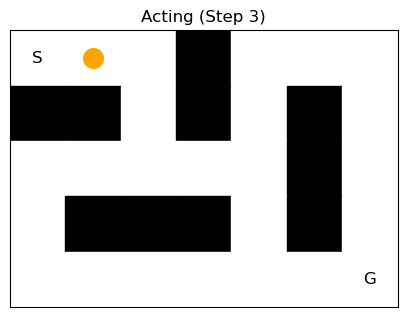

...

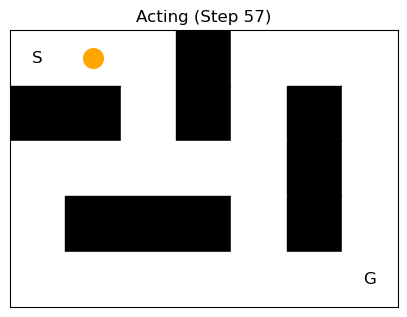

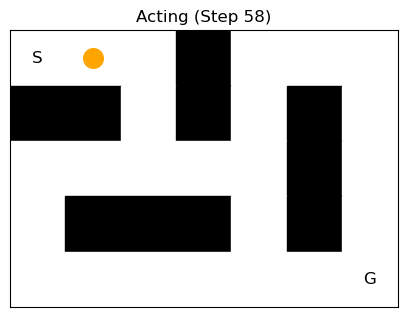

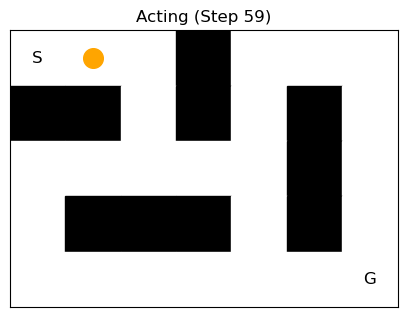

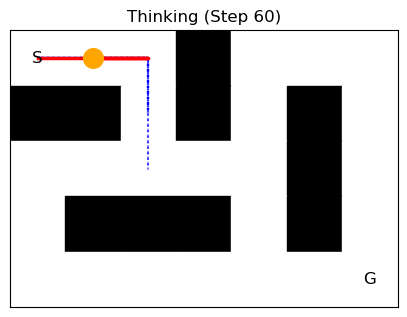

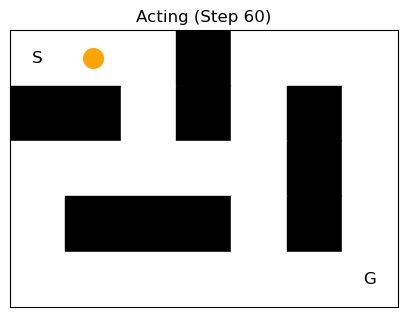

❌ Episode ended without reaching goal


In [75]:
agent_plan = Agent(
    epsilon=0.5,
    imagination_horizon=6,
    imagination_rollouts=12
)

run_agent_episode(env, agent_plan, max_steps=60, delay=0.3)

## World-Model Coverage Diagnosis
We need to answer one question only:

`Does the agent even know a path to the goal in its world model?`

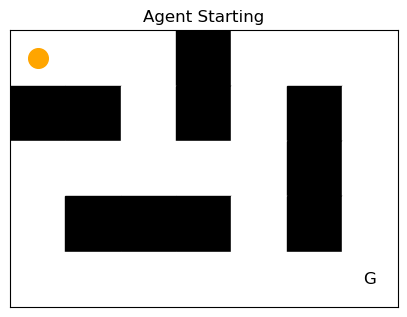

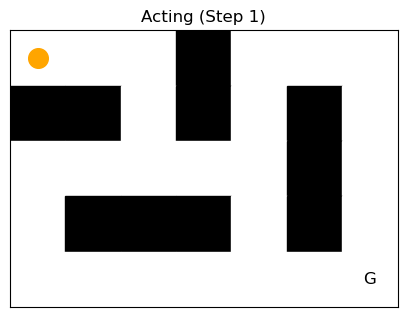

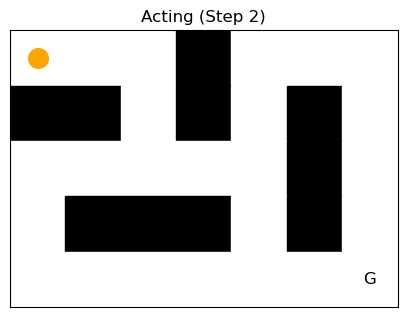

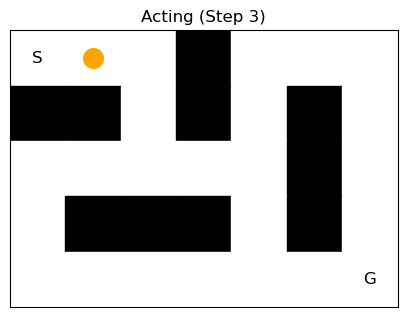

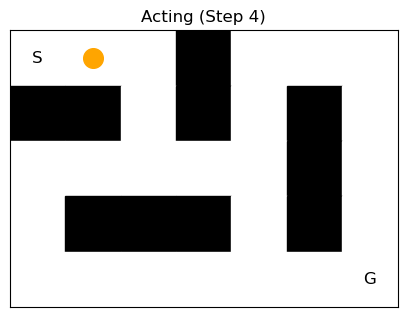

...

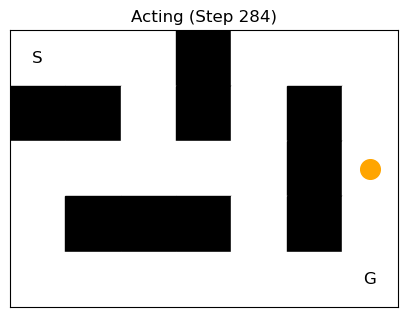

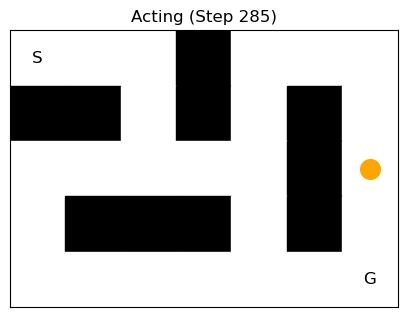

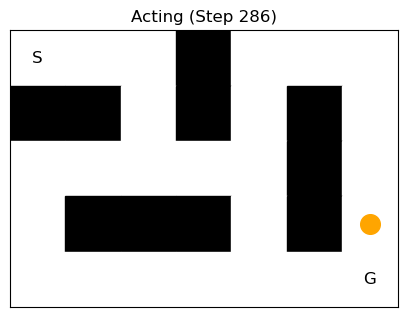

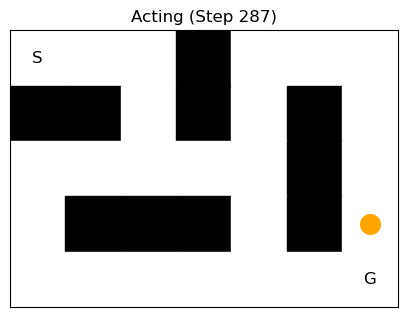

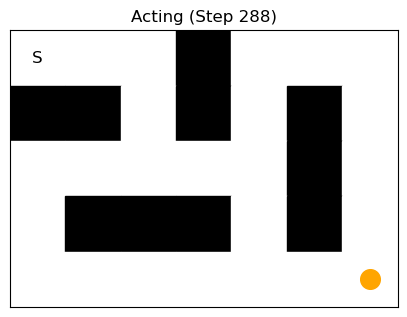

🎯 Reached goal in 288 steps


In [79]:
agent_plan = Agent(
    epsilon=1.0, #High exploration
    imagination_horizon=12,
    imagination_rollouts=24
)

run_agent_episode(env, agent_plan, max_steps=500, delay=0.3) #longer Steps

**Yes it does**
## Next Step : Compare Planning and Exploration phase

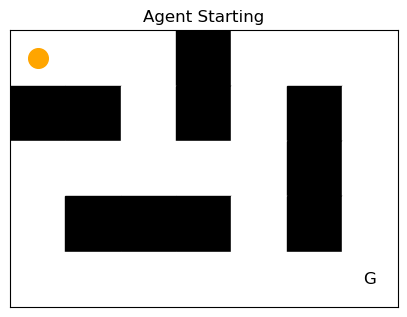

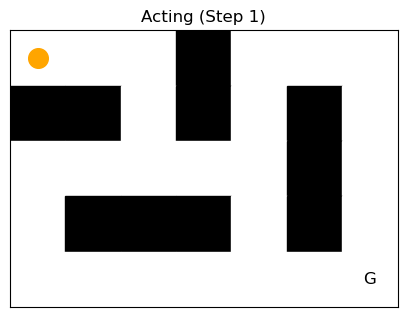

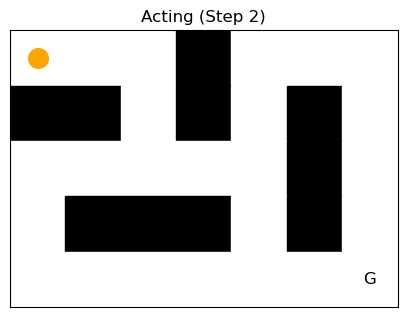

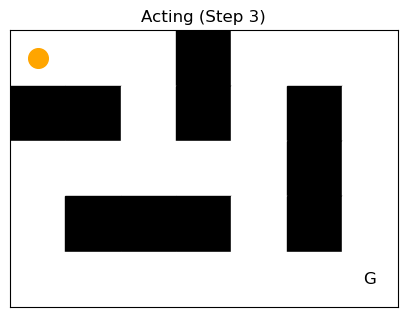

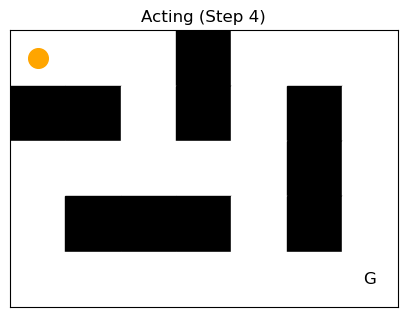

...

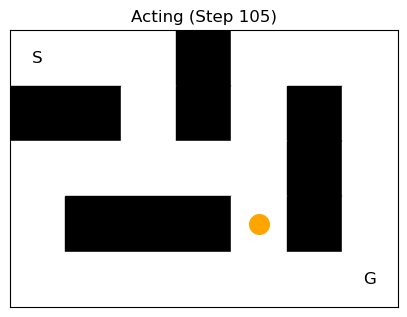

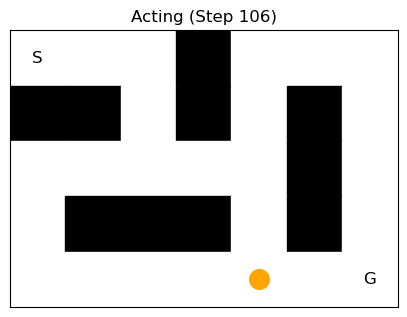

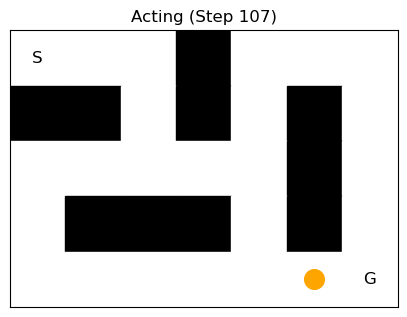

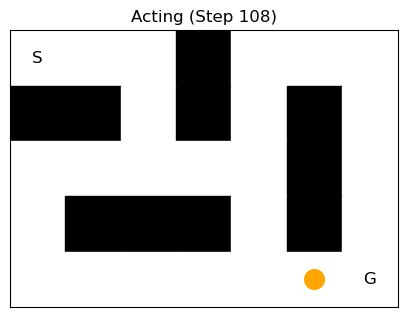

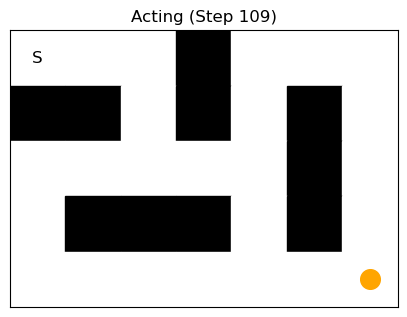

🎯 Reached goal in 109 steps


In [80]:
# Exploration
agent_plan = Agent(
    epsilon=1.0, #High exploration
    imagination_horizon=12,
    imagination_rollouts=24
)

run_agent_episode(env, agent_plan, max_steps=500, delay=0.3) #longer Steps

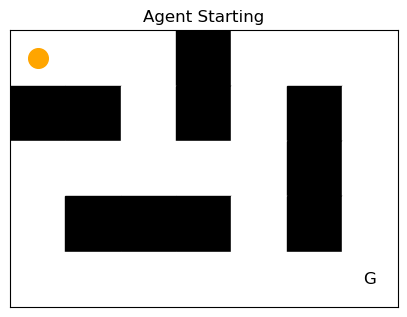

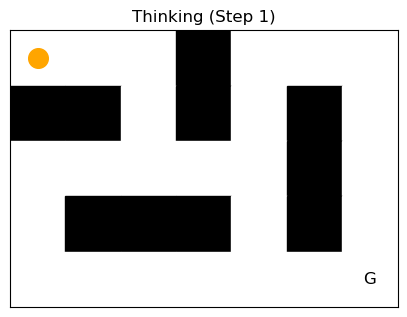

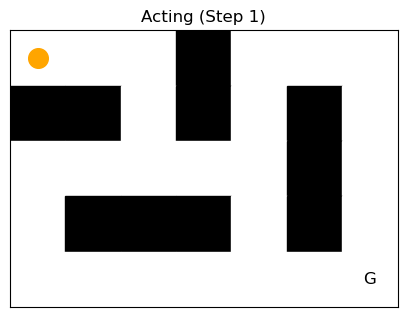

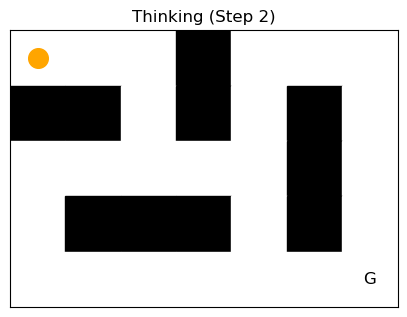

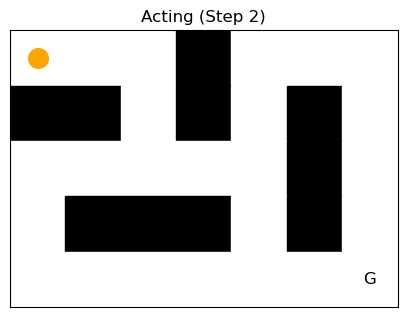

...

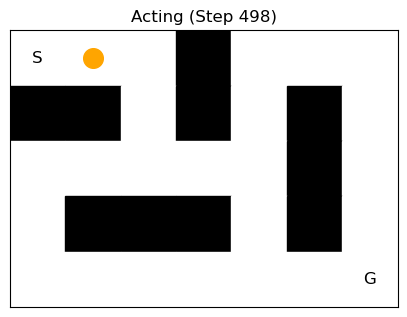

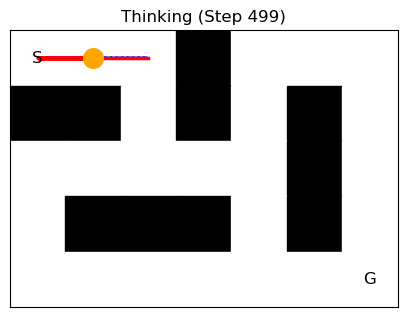

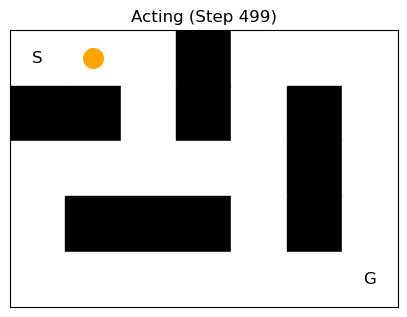

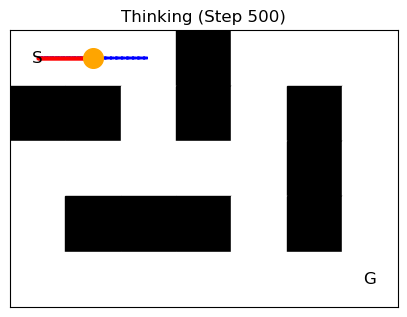

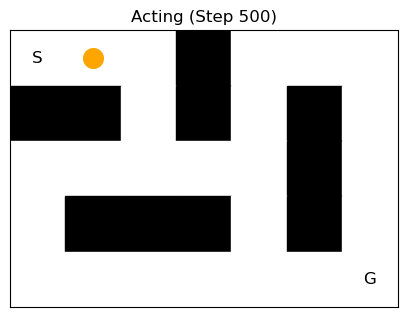

❌ Episode ended without reaching goal


In [81]:
#Planning
agent_plan = Agent(
    epsilon=0.05, #High planning
    imagination_horizon=12,
    imagination_rollouts=24
)

run_agent_episode(env, agent_plan, max_steps=500, delay=0.3) #longer Steps

**Planning without value grounding does not imply goal-directed behavior.**

This is a real insight.
Many people assume:

`“If an agent can imagine, it will plan.”`

Our system shows:

`Imagination ≠ Planning unless futures are evaluated meaningfully.`

That’s a core cognitive claim.